# Tercer Taller
## Maestría en Matemáticas y Ciencias de la Computación
## Universidad del Rosario

**El modelo de riqueza de Boltzmann**

La premisa de este tutorial es crear un modelo de nivel inicial que represente a agentes que intercambian dinero. Este intercambio de dinero afecta la riqueza.

A continuación, se agrega *espacio* para permitir que los agentes se muevan en función del cambio en la riqueza a medida que avanza el tiempo.

Luego se utilizan dos de las herramientas analíticas de Mesa: el *recopilador de datos* y el *ejecutor de lotes* para examinar la dinámica de este modelo simple.

## Descripción del modelo

Se trata de una economía basada en agentes simulada de nivel inicial. En una economía basada en agentes, se estudia el comportamiento de un agente económico individual, como un consumidor o un productor, en un entorno de mercado [[Drăgulescu, 2002]](https://arxiv.org/pdf/cond-mat/0211175).

Los supuestos que rigen este modelo son:

1. Hay una cierta cantidad de agentes.
2. Todos los agentes comienzan con 1 unidad de dinero.
3. En cada paso del modelo, un agente da 1 unidad de dinero (si la tiene) a otro agente.

Estos pasos elementales permiten describir sistemas económicos complejos con predicciones consistentes.

Inicio - Instalación de paquetes

El signo % es llamado *Magic Comand* es recomendado en entornos interactivos en los se se ejecutan códigos por secciones.

In [1]:
%pip install mesa --quiet

/Users/oh/World/External/Study/UR/IAPS-I/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


Este código funciona para la versión 3.5.1 de mesa

In [1]:
import mesa
print(mesa.__version__)

3.5.1


Importar librerías

In [2]:
# Herramientas de visualización
import seaborn as sns
import matplotlib.pyplot as plt

# Herramienta para cálculo numérico y para manipulación de arreglos (vectores y matrices)
import numpy as np

# Herramienta para la creación, lectura y manipulación de DataFrames
import pandas as pd

**Crear agentes**

Modelo: Los agentes son individuos que intercambian dinero, en este caso la cantidad de dinero que tiene un agente representa su riqueza (wealth). Cada agente tiene un número de identificación único.

Implementación: Se crea una nueva clase (y nuevos objetos) que extiende mesa.Agent y crea una subclase de la clase Agent de mesa. La nueva clase es llamada MoneyAgent.

In [3]:
class MoneyAgent(mesa.Agent):
    """An agent with fixed initial wealth."""

    def __init__(self, model):
        # Pass the parameters to the parent class.
        super().__init__(model)

        # Create the agent's variable and set the initial values.
        self.wealth = 1

Recordar la revisión hecha respecto a la **herencia** de clases.

**Crear modelo**

Ahora se crea el modelo. Progresivamente se agregan funciones al modelo.

**Información específica del modelo:** Cuando se crea un modelo, se especifica la cantidad de agentes dentro del modelo. El modelo también contiene un programador (agenda) que controla el orden en el que se activan los agentes. El programador también es responsable de avanzar el modelo un paso. El modelo también contiene un recopilador de datos que recopila datos del modelo. Estos temas se tratarán con más detalle más adelante en el tutorial.

Se crea una nueva clase llamada `MoneyModel`.

In [4]:
class MoneyModel(mesa.Model):
    """A model with some number of agents."""

    def __init__(self, n, seed = None):
        super().__init__(seed = seed)
        self.num_agents = n
        # Create agents
        MoneyAgent.create_agents(model = self, n = n)

**Hacer que los agentes** ``hagan``

Una vez creados los conceptos básicos de la clase Agente y la clase Modelo, ahora podemos activar los agentes para que hagan cosas.

**Antecedentes**: La función `do` de Mesa invoca funciones de agente para hacer crecer su ABM (Agent-Based Model). Un paso es la unidad de tiempo más pequeña del modelo y, a menudo, se lo denomina tick. La función do y la funcionalidad de Python se pueden configurar para activar agentes en diferentes órdenes. Esto puede ser importante, ya que el orden en el que se activan los agentes puede afectar los resultados del modelo. En cada paso del modelo, uno o más de los agentes (normalmente todos) se activan y realizan su propio paso, cambiando internamente o interactuando entre sí o con el entorno.

**Información específica del modelo**: Para esta sección, reordenaremos aleatoriamente el orden de activación del agente utilizando mesa.Agent.shuffle_do y haremos que la función de paso de los agentes imprima la identificación única del agente que se les asignó durante el proceso de creación del agente.

**Implementación del código**: Utilizando la convención estándar de ABM, agregamos una función de paso a la clase MoneyModel que invoca la función mesa.Agent.shuffle_do. Luego pasamos a shuffle_do el parámetro "step". Esto le indica a mesa que busque y ejecute la función step en nuestra clase MoneyAgent.

In [5]:
class MoneyAgent(mesa.Agent):
    """An agent with fixed initial wealth."""

    def __init__(self, model):
        # Pass the parameters to the parent class.
        super().__init__(model)

        # Create the agent's attribute and set the initial values.
        self.wealth = 1

    def say_hi(self):
        # The agent's step will go here.
        # For demonstration purposes we will print the agent's unique_id
        print(f"Hi, I am an agent, you can call me {str(self.unique_id)}.")


class MoneyModel(mesa.Model):
    """A model with some number of agents."""

    def __init__(self, n, rng = None): # Intercambiar None por 42
        super().__init__(rng=rng)
        self.num_agents = n

        # Create n agents
        MoneyAgent.create_agents(model = self, n = n)

    def step(self):
        """Advance the model by one step."""

        # This function psuedo-randomly reorders the list of agent objects and
        # then iterates through calling the function passed in as the parameter
        self.agents.shuffle_do("say_hi")
        #self.agents.do("say_hi")

Corriendo el modelo

In [6]:
starter_model = MoneyModel(10)
starter_model.step()

Hi, I am an agent, you can call me 7.
Hi, I am an agent, you can call me 2.
Hi, I am an agent, you can call me 3.
Hi, I am an agent, you can call me 1.
Hi, I am an agent, you can call me 9.
Hi, I am an agent, you can call me 5.
Hi, I am an agent, you can call me 6.
Hi, I am an agent, you can call me 8.
Hi, I am an agent, you can call me 10.
Hi, I am an agent, you can call me 4.


## <font color="red"> **Ejercicios** </font>

* ¿Se tiene el mismo resultado en cada ejecución del código?
* ¿Cuál es la diferencia entre usar `shuffle_do` o `do`?
* ¿Qué pasa al fijar una semilla? Fijar `seed = 42`

### <font color="green"> Respuestas </font>

* **¿Se tiene el mismo resultado en cada ejecución?** No. `shuffle_do` baraja a los agentes
  en cada tick con el generador aleatorio del modelo, y ese generador se siembra al azar si
  no se le dice otra cosa. Dos ejecuciones seguidas activan a los agentes en órdenes
  distintos.
* **¿Qué pasa al fijar una semilla?** Con `MoneyModel(6, rng=42)` el orden se repite
  exactamente. Es la diferencia entre tener un resultado y tener un resultado
  *reproducible*: sin semilla no se puede depurar un modelo ni comparar dos variantes, y
  cualquier diferencia entre dos corridas puede ser el cambio o puede ser el azar.
* **¿`do` o `shuffle_do`?** `do` activa siempre en el orden de creación; `shuffle_do`
  permuta ese orden en cada tick. La diferencia no es cosmética: con `do`, la riqueza medida
  al final del tick depende de **la posición del agente en el orden**. En 200 réplicas de 50
  pasos con 20 agentes, el primero termina con 1.30 unidades y el último con 0.69 — aunque
  ambos entregan lo mismo (34.4 contra 34.5 entregas). La causa es la fase dentro del tick:
  el que actúa primero entrega al comienzo y tiene el resto del tick para recibir; el que
  actúa último acaba de entregar justo cuando tomamos la foto. `shuffle_do` reparte esa fase
  al azar y el perfil queda plano.

sin semilla:   [2, 4, 6, 3, 5, 1]
sin semilla:   [1, 4, 2, 3, 5, 6]
con rng = 42:  [4, 2, 3, 5, 1, 6]
con rng = 42:  [4, 2, 3, 5, 1, 6]


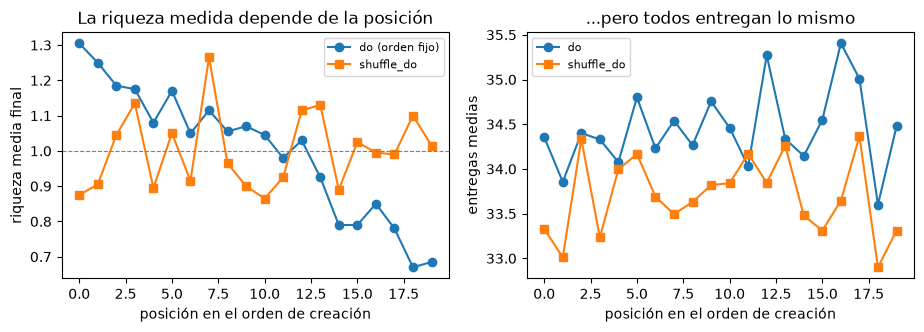

do:         riqueza primero 1.30 / último 0.69   entregas 34.4 / 34.5
shuffle_do: riqueza primero 0.88 / último 1.01   entregas 33.3 / 33.3


In [7]:
import contextlib
import io


def orden_de_activacion(modelo):
    """Los `unique_id` en el orden en que el modelo activó a los agentes."""
    salida = io.StringIO()
    with contextlib.redirect_stdout(salida):
        modelo.step()
    return [int(l.split("call me ")[1].rstrip(".")) for l in salida.getvalue().splitlines()]


print("sin semilla:  ", orden_de_activacion(MoneyModel(6)))
print("sin semilla:  ", orden_de_activacion(MoneyModel(6)))
print("con rng = 42: ", orden_de_activacion(MoneyModel(6, rng=42)))
print("con rng = 42: ", orden_de_activacion(MoneyModel(6, rng=42)))


# `do` contra `shuffle_do`: la diferencia no se ve saludando, se ve en la riqueza. Este
# modelo auxiliar es el del intercambio, con el orden de activación como parámetro.
class AgenteOrden(mesa.Agent):
    def __init__(self, model):
        super().__init__(model)
        self.wealth = 1
        self.entregas = 0

    def exchange(self):
        if self.wealth > 0:
            self.entregas += 1
            self.random.choice(self.model.agents).wealth += 1
            self.wealth -= 1


class ModeloOrden(mesa.Model):
    def __init__(self, n, orden="shuffle_do", rng=None):
        super().__init__(rng=rng)
        self.num_agents = n
        self.orden = orden
        AgenteOrden.create_agents(model=self, n=n)

    def step(self):
        if self.orden == "shuffle_do":
            self.agents.shuffle_do("exchange")
        else:
            self.agents.do("exchange")


def perfiles(orden, n=20, pasos=50, replicas=200):
    """Riqueza final y entregas acumuladas de cada agente, por su orden de creación."""
    riqueza, entregas = np.zeros(n), np.zeros(n)
    for r in range(replicas):
        m = ModeloOrden(n, orden=orden, rng=r)
        for _ in range(pasos):
            m.step()
        ordenados = sorted(m.agents, key=lambda a: a.unique_id)
        riqueza += [a.wealth for a in ordenados]
        entregas += [a.entregas for a in ordenados]
    return riqueza / replicas, entregas / replicas


riqueza_do, entregas_do = perfiles("do")
riqueza_sh, entregas_sh = perfiles("shuffle_do")

fig, (izq, der) = plt.subplots(1, 2, figsize=(11, 3.2))
izq.plot(riqueza_do, "o-", label="do (orden fijo)")
izq.plot(riqueza_sh, "s-", label="shuffle_do")
izq.axhline(1, color="grey", ls="--", lw=0.8)
izq.set(xlabel="posición en el orden de creación", ylabel="riqueza media final",
        title="La riqueza medida depende de la posición")
der.plot(entregas_do, "o-", label="do")
der.plot(entregas_sh, "s-", label="shuffle_do")
der.set(xlabel="posición en el orden de creación", ylabel="entregas medias",
        title="...pero todos entregan lo mismo")
izq.legend(fontsize=8)
der.legend(fontsize=8)
plt.show()

print(f"do:         riqueza primero {riqueza_do[0]:.2f} / último {riqueza_do[-1]:.2f}   "
      f"entregas {entregas_do[0]:.1f} / {entregas_do[-1]:.1f}")
print(f"shuffle_do: riqueza primero {riqueza_sh[0]:.2f} / último {riqueza_sh[-1]:.2f}   "
      f"entregas {entregas_sh[0]:.1f} / {entregas_sh[-1]:.1f}")

* Modificar el código a continuación para que cada agente imprima su "riqueza" cuando se activa. Cree un modelo para 12 agentes y ejecútelo durante algunos pasos para ver el resultado.

In [8]:
class MoneyAgent(mesa.Agent):
    """An agent with fixed initial wealth."""

    def __init__(self, model):
        # Pass the parameters to the parent class.
        super().__init__(model)

        # Create the agent's variable and set the initial values.
        self.wealth = 1

    def say_wealth(self):
        # The agent's step will go here.
        # FIXME: need to print the agent's wealth
        print(f"Hi, I am an agent, you can call me {str(self.unique_id)}. And I have {str(self.wealth)} units of wealth.")

class MoneyModel(mesa.Model):
    """A model with some number of agents."""

    def __init__(self, n, rng = None): # Intercambiar None por 42
        super().__init__(rng = rng)
        self.num_agents = n

        # Create n agents
        MoneyAgent.create_agents(model = self, n = n)

    def step(self):
        """Advance the model by one step."""

        # This function psuedo-randomly reorders the list of agent objects and
        # then iterates through calling the function passed in as the parameter
        self.agents.shuffle_do("say_wealth")
        #self.agents.do("say_hi")

In [9]:
starter_model = MoneyModel(12)
starter_model.step()

Hi, I am an agent, you can call me 6. And I have 1 units of wealth.
Hi, I am an agent, you can call me 8. And I have 1 units of wealth.
Hi, I am an agent, you can call me 5. And I have 1 units of wealth.
Hi, I am an agent, you can call me 3. And I have 1 units of wealth.
Hi, I am an agent, you can call me 9. And I have 1 units of wealth.
Hi, I am an agent, you can call me 12. And I have 1 units of wealth.
Hi, I am an agent, you can call me 10. And I have 1 units of wealth.
Hi, I am an agent, you can call me 4. And I have 1 units of wealth.
Hi, I am an agent, you can call me 7. And I have 1 units of wealth.
Hi, I am an agent, you can call me 2. And I have 1 units of wealth.
Hi, I am an agent, you can call me 1. And I have 1 units of wealth.
Hi, I am an agent, you can call me 11. And I have 1 units of wealth.


Solución:

In [10]:
# Ejercicio: 12 agentes, varios pasos. `say_wealth` ya imprime la riqueza de cada uno.
modelo12 = MoneyModel(12, rng=42)
for paso in range(2):
    print(f"--- paso {paso + 1}")
    modelo12.step()

--- paso 1
Hi, I am an agent, you can call me 8. And I have 1 units of wealth.
Hi, I am an agent, you can call me 6. And I have 1 units of wealth.
Hi, I am an agent, you can call me 3. And I have 1 units of wealth.
Hi, I am an agent, you can call me 9. And I have 1 units of wealth.
Hi, I am an agent, you can call me 10. And I have 1 units of wealth.
Hi, I am an agent, you can call me 7. And I have 1 units of wealth.
Hi, I am an agent, you can call me 12. And I have 1 units of wealth.
Hi, I am an agent, you can call me 4. And I have 1 units of wealth.
Hi, I am an agent, you can call me 5. And I have 1 units of wealth.
Hi, I am an agent, you can call me 1. And I have 1 units of wealth.
Hi, I am an agent, you can call me 2. And I have 1 units of wealth.
Hi, I am an agent, you can call me 11. And I have 1 units of wealth.
--- paso 2
Hi, I am an agent, you can call me 6. And I have 1 units of wealth.
Hi, I am an agent, you can call me 8. And I have 1 units of wealth.
Hi, I am an agent, you 

**Paso del agente**

Volviendo a MoneyAgent, ahora se creará el proceso de intercambio real.

**Antecedentes**: aquí es donde se define el comportamiento del agente en relación con cada paso o marca del modelo.

**Información específica del modelo**: en este caso, el agente verificará su riqueza y, si tiene dinero, regalará una unidad de este a otro agente aleatorio.

**Implementación del código**: el método de paso del agente es llamado por mesa.Agent.shuffle_do("exchange") durante cada paso del modelo. Para permitir que el agente elija otro agente al azar, usamos el generador de números aleatorios model.random. Esto funciona igual que el módulo aleatorio de Python, pero si se establece un conjunto de semillas fijo cuando se crea una instancia del modelo (consulte el desafío anterior), esto permite a los usuarios replicar una ejecución de modelo específica más tarde. Una vez que identificamos este otro objeto de agente, aumentamos su riqueza en 1 y disminuimos la riqueza de este agente en uno.

Esto actualiza la función de paso como se muestra a continuación

In [11]:
class MoneyAgent(mesa.Agent):
    """An agent with fixed initial wealth."""

    def __init__(self, model):
        # Pass the parameters to the parent class.
        super().__init__(model)

        # Create the agent's variable and set the initial values.
        self.wealth = 1

    def exchange(self):
        # Verify agent has some wealth
        if self.wealth > 0:
            other_agent = self.random.choice(self.model.agents)
            if other_agent is not None:
                  other_agent.wealth += 1  # ?
                  self.wealth -= 1  # ?


class MoneyModel(mesa.Model):
    """A model with some number of agents."""

    def __init__(self, n):
        super().__init__()
        self.num_agents = n

        # Create agents
        MoneyAgent.create_agents(model=self, n=n)

    def step(self):
        """Advance the model by one step."""

        # This function psuedo-randomly reorders the list of agent objects and
        # then iterates through calling the function passed in as the parameter
        self.agents.shuffle_do("exchange")

### Ejecución de su primer modelo

Con esa última pieza en la mano, es hora de la primera ejecución rudimentaria del modelo.

Ahora, creemos un modelo con 10 agentes y ejecútelo durante 15 pasos.

In [12]:
model = MoneyModel(10)  # Tells the model to create 10 agents
for _ in range(15):  # Runs the model for 15 steps
    model.step()

A continuación, necesitamos obtener algunos datos del modelo. En concreto, queremos ver la distribución de la riqueza del agente. Podemos obtener los valores de riqueza con **comprensión de listas** y, a continuación, utilizar Seaborn para visualizar los datos en un histograma.

In [13]:
agent_wealth = [a.wealth for a in model.agents]
agent_wealth

[1, 1, 0, 3, 0, 1, 0, 2, 0, 2]

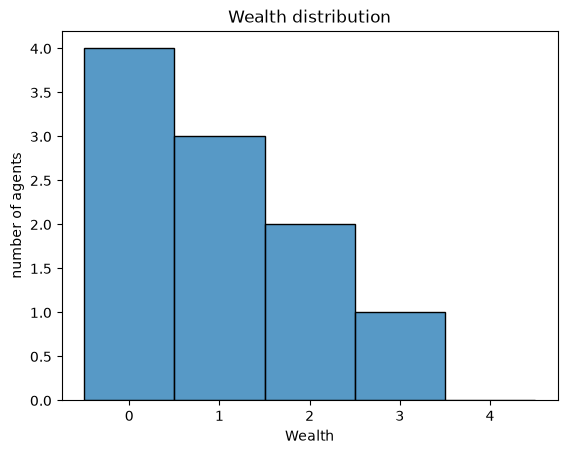

In [14]:
# Create a histogram with seaborn
g = sns.histplot(agent_wealth, discrete=True, binrange=(0, 4))
g.set(title="Wealth distribution", xlabel="Wealth", ylabel="number of agents");
    # The semicolon is just to avoid printing the object representation

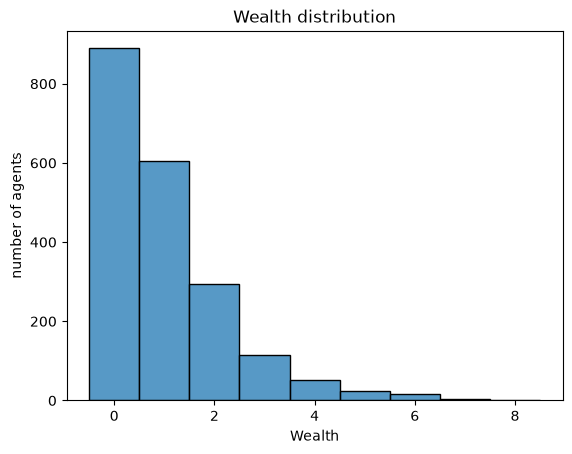

In [15]:
all_wealth = []
# This runs the model 100 times, each model executing 10 steps.
for _ in range(100): # 100 repeticiones del experimento
    # Run the model
    model = MoneyModel(20) # 20 agentes
    for _ in range(20): # 20 pasos o rondas de juego
        model.step()

    # Store the results
    for agent in model.agents:
        all_wealth.append(agent.wealth)

# Use seaborn
g = sns.histplot(all_wealth, discrete=True)
g.set(title="Wealth distribution", xlabel="Wealth", ylabel="number of agents");

Deberían ver algo parecido a la distribución anterior. Es casi seguro que la de ustedes se verá al menos ligeramente diferente, ya que cada ejecución del modelo es aleatoria.

## Ver el estado y las acciones cambiar

Las figuras de arriba muestran el **resultado**: un histograma después de 20 pasos. Pero un
ABM no es un resultado, es una *trayectoria*, y lo que produce la desigualdad es el camino.
Conviene nombrar las dos cosas que definen cualquier modelo de agentes:

* **Estado** *s*: lo mínimo que hay que conocer para poder continuar la simulación. En esta
  etapa es solo el vector de riquezas $(w_1, \dots, w_N)$. Como la riqueza total $W$ se
  conserva, el número de estados posibles es el de repartos de $W$ unidades entre $N$
  agentes, $\binom{W+N-1}{N-1}$: con 20 agentes son ~$10^{11}$ estados. Ese número es la
  razón por la que un ABM **se simula y no se resuelve enumerando**.
* **Acción** *a*: lo que un agente puede hacer en un tick. Aquí, dar una unidad a uno de los
  $N$ agentes, o no hacer nada si está en cero.

La celda siguiente define las utilidades de traza —se reutilizan al final del cuaderno— y la
que sigue anima la corrida. Cada flecha naranja es una transferencia de ese tick.

> El reproductor tiene play, pausa y un deslizador: la gracia es parar en un tick concreto.
> El peso del cuaderno lo deciden `pasos` y `dpi`; bájalos si se vuelve pesado.

In [16]:
# Utilidades de traza y dibujo. Se definen una sola vez y se usan en las dos animaciones.
import math
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Rectangle
from IPython.display import HTML


def gini_de(riquezas):
    """Coeficiente de Gini de una lista de riquezas (0 = igualdad total)."""
    x = sorted(riquezas)
    n = len(x)
    s = sum(x)
    if n == 0 or s == 0:
        return 0.0
    B = sum(xi * (n - i) for i, xi in enumerate(x)) / (n * s)
    return 1 + (1 / n) - 2 * B


def instantanea(model):
    """El ESTADO del sistema en este tick, más las ACCIONES que acaban de ocurrir.

    El estado de este ABM es exactamente esto: la riqueza de cada agente y —cuando hay
    espacio— su posición. Todo lo demás (Gini, total, celdas vacías) se deriva de ahí.
    """
    agentes = list(model.agents)
    riqueza = {a.unique_id: a.wealth for a in agentes}
    return {
        "tick": model.steps,
        "riqueza": riqueza,
        "pos": {a.unique_id: a.pos for a in agentes if getattr(a, "pos", None)},
        "movimientos": list(getattr(model, "movimientos", [])),
        "transferencias": list(getattr(model, "transferencias", [])),
        "gini": gini_de(riqueza.values()),
        "total": sum(riqueza.values()),
    }


def traza(model, pasos):
    """Correr el modelo guardando una instantánea por tick (más el estado inicial)."""
    instantaneas = [instantanea(model)]
    for _ in range(pasos):
        model.step()
        instantaneas.append(instantanea(model))
    return instantaneas


def _jitter(ids, semilla=0):
    """Desplazamiento fijo de cada agente dentro de su celda, para no apilarlos.

    Es determinista por `unique_id`: si cambiara entre frames, los agentes vibrarían y
    parecería que se mueven cuando no lo hacen.
    """
    rng = np.random.default_rng(semilla)
    return {i: (rng.uniform(-0.3, 0.3), rng.uniform(-0.3, 0.3)) for i in sorted(ids)}


def _panel_estado_lineal(ax, snaps, i):
    """Sin espacio: los agentes en fila, tamaño = riqueza, flechas = intercambios."""
    s = snaps[i]
    ax.clear()
    ids = sorted(s["riqueza"])
    xs = list(range(len(ids)))
    w = [s["riqueza"][k] for k in ids]
    ax.scatter(xs, [0] * len(xs), s=[60 + 90 * v for v in w], c=w, cmap="viridis",
               vmin=0, vmax=max(3, max(w)), zorder=3)
    for x, k in zip(xs, ids):
        ax.annotate(str(s["riqueza"][k]), (x, 0), xytext=(0, -18),
                    textcoords="offset points", ha="center", fontsize=7, color="#444444")
    donde = {k: x for x, k in zip(xs, ids)}
    for da, recibe in s["transferencias"]:
        if da in donde and recibe in donde and da != recibe:
            ax.annotate("", xy=(donde[recibe], 0), xytext=(donde[da], 0),
                        arrowprops=dict(arrowstyle="->", color="#ff7f0e", lw=1.0,
                                        alpha=0.55,
                                        connectionstyle="arc3,rad=0.3"), zorder=4)
    ax.set_xlim(-1, len(ids))
    ax.set_ylim(-0.6, 0.8)
    ax.set_yticks([])
    ax.set_xticks([])
    ax.set_title(f"Estado: riqueza de cada agente  ·  tick {s['tick']}", fontsize=10)


def _panel_estado_grilla(ax, snaps, i, forma, jit):
    """Con espacio: la grilla, los agentes coloreados por riqueza y lo que hicieron."""
    s = snaps[i]
    ancho, alto = forma
    ax.clear()
    ax.set_xticks(np.arange(-0.5, ancho, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, alto, 1), minor=True)
    ax.grid(which="minor", color="#dddddd", lw=0.6)
    ax.tick_params(which="both", length=0, labelsize=7)

    def punto(uid, celda):
        dx, dy = jit[uid]
        return celda[0] + dx, celda[1] + dy

    for uid, desde, hasta in s["movimientos"]:
        x0, y0 = punto(uid, desde)
        x1, y1 = punto(uid, hasta)
        if abs(x1 - x0) < 2 and abs(y1 - y0) < 2:  # el toro da saltos largos: no se dibujan
            ax.plot([x0, x1], [y0, y1], color="#999999", lw=0.6, alpha=0.35, zorder=2)

    ids = sorted(s["riqueza"])
    px, py, pw = [], [], []
    for uid in ids:
        celda = s["pos"].get(uid)
        if celda is None:
            continue
        x, y = punto(uid, celda)
        px.append(x)
        py.append(y)
        pw.append(s["riqueza"][uid])
    ax.scatter(px, py, s=[22 + 26 * v for v in pw], c=pw, cmap="viridis",
               vmin=0, vmax=max(3, max(pw)), zorder=4, edgecolors="white", linewidths=0.4)

    for celda_da, celda_recibe, uid_da, uid_recibe in s["transferencias"]:
        x0, y0 = punto(uid_da, celda_da)
        x1, y1 = punto(uid_recibe, celda_recibe)
        ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                    arrowprops=dict(arrowstyle="->", color="#ff7f0e", lw=1.1, alpha=0.9),
                    zorder=5)

    ax.set_xlim(-0.5, ancho - 0.5)
    ax.set_ylim(-0.5, alto - 0.5)
    ax.set_aspect("equal")
    ax.set_title(f"Estado: posición y riqueza  ·  tick {s['tick']}", fontsize=10)


def _panel_heatmap(ax, snaps, i, forma, tope):
    """El heatmap de `agent_counts` del tutorial, pero tick a tick.

    Es el mismo estado del panel de la izquierda visto como densidad: ahí se ven los
    agentes, aquí se ve cuántos hay por celda —incluidas las que se quedan en cero—.
    """
    s = snaps[i]
    ancho, alto = forma
    cuentas = np.zeros((ancho, alto))
    for celda in s["pos"].values():
        cuentas[celda] += 1

    ax.clear()
    ax.imshow(cuentas.T, origin="lower", cmap="viridis", vmin=0, vmax=tope)
    for (x, y), n in np.ndenumerate(cuentas):
        if n:
            ax.text(x, y, f"{int(n)}", ha="center", va="center", fontsize=6.5,
                    color="white" if n < tope * 0.6 else "black")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect("equal")
    vacias = int((cuentas == 0).sum())
    ax.set_title(f"Agentes por celda  ·  {vacias} vacías", fontsize=10)


def _panel_acciones(ax, snaps, i, forma):
    """El ESPACIO DE ACCIONES: qué puede hacer un agente y qué hizo en este tick."""
    s = snaps[i]
    ax.clear()
    ax.axis("off")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

    n = len(s["riqueza"])
    n_mueve = len(s["movimientos"])
    n_da = len(s["transferencias"])
    acciones = [("MOVE", n_mueve), ("GIVE", n_da), ("IDLE", n - n_da)]
    if forma is None:
        acciones = [("GIVE", n_da), ("IDLE", n - n_da)]

    ancho = 1.0 / len(acciones)
    for k, (nombre, cuenta) in enumerate(acciones):
        activa = cuenta > 0
        ax.add_patch(Rectangle((k * ancho + 0.02, 0.55), ancho - 0.04, 0.32,
                               facecolor="#1f77b4" if activa else "#eeeeee",
                               edgecolor="#cccccc", lw=0.8))
        ax.text(k * ancho + ancho / 2, 0.71, f"{nombre}\n{cuenta}", ha="center",
                va="center", fontsize=8.5, color="white" if activa else "#888888",
                weight="bold" if activa else "normal")

    if forma is None:
        texto = ("A(s) = {dar 1 unidad a un agente al azar, no hacer nada}\n"
                 f"|A(s)| = {n} destinos posibles por agente")
    else:
        celdas = {}
        for uid, celda in s["pos"].items():
            celdas.setdefault(celda, []).append(uid)
        compis = (sum(len(v) - 1 for v in celdas.values()) / max(1, len(s["pos"])))
        texto = ("A(s) = (mover a 1 de 8 vecinos Moore) × (dar a 1 compañero de celda | nada)\n"
                 f"|A(s)| ≈ 8 × ({compis:.1f} + 1) ≈ {8 * (compis + 1):.0f} por agente")
    ax.text(0.02, 0.34, texto, fontsize=8, va="top", color="#444444")
    ax.set_title("Acciones ejecutadas en este tick", fontsize=10, loc="left")


def _panel_espacio_estados(ax, snaps, i, forma):
    """Cuán grande es el espacio de estados, y qué parte de él se está ocupando."""
    s = snaps[i]
    ax.clear()
    ax.axis("off")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_title("Espacio de estados", fontsize=10, loc="left")

    n = len(s["riqueza"])
    w = int(s["total"])
    # Repartos posibles de W unidades entre N agentes: C(W+N-1, N-1). Se calcula en
    # logaritmo porque el número no cabe en un float.
    log_repartos = (math.lgamma(w + n) - math.lgamma(n) - math.lgamma(w + 1)) / math.log(10)
    lineas = [
        f"N = {n} agentes,  W = {w} unidades",
        f"repartos de riqueza: C(W+N−1, N−1) ≈ 10^{log_repartos:.0f}",
    ]
    if forma is not None:
        celdas = forma[0] * forma[1]
        log_pos = n * math.log10(celdas)
        lineas += [
            f"posiciones: {celdas}^{n} ≈ 10^{log_pos:.0f}",
            f"|S| ≈ 10^{log_pos + log_repartos:.0f}   (no se enumera: se simula)",
            "",
            f"celdas ocupadas: {len(set(s['pos'].values()))} de {celdas}",
        ]
    else:
        lineas += [f"|S| ≈ 10^{log_repartos:.0f}   (no se enumera: se simula)", ""]
    lineas += [
        f"riquezas distintas: {len(set(s['riqueza'].values()))}",
        f"máxima: {max(s['riqueza'].values())}   ·   Gini: {s['gini']:.3f}",
        f"riqueza total: {w}  (¿se conserva?)",
    ]
    paso_y = 0.86 / max(4, len(lineas))
    for k, linea in enumerate(lineas):
        ax.text(0.02, 0.9 - k * paso_y, linea, fontsize=7.5, family="monospace",
                va="top", color="#333333")


def _panel_histograma(ax, snaps, i, tope_y, tope_x):
    """La distribución de riqueza deformándose tick a tick."""
    s = snaps[i]
    ax.clear()
    ax.hist(list(s["riqueza"].values()), bins=np.arange(-0.5, tope_x + 1.5, 1),
            color="#4c72b0")
    ax.set_xlim(-0.5, tope_x + 0.5)
    ax.set_ylim(0, tope_y)
    ax.set_xlabel("riqueza", fontsize=8)
    ax.set_ylabel("agentes", fontsize=8)
    ax.tick_params(labelsize=7)
    ax.set_title("Distribución de riqueza", fontsize=10)


def _panel_gini(ax, snaps, i):
    """El Gini creciendo: el resultado agregado que producen las reglas locales."""
    ticks = [s["tick"] for s in snaps]
    ginis = [s["gini"] for s in snaps]
    ax.clear()
    ax.plot(ticks[: i + 1], ginis[: i + 1], color="#c44e52", lw=1.6)
    ax.axvline(ticks[i], color="#bbbbbb", lw=0.8, ls="--")
    ax.set_xlim(0, max(ticks))
    ax.set_ylim(0, max(0.2, max(ginis) * 1.15))
    ax.set_xlabel("tick", fontsize=8)
    ax.tick_params(labelsize=7)
    ax.set_title(f"Gini = {ginis[i]:.3f}", fontsize=10)


def animar_modelo(snaps, *, forma=None, titulo="", ms=350, dpi=72, figsize=(13.0, 7.0)):
    """Animar una traza: estado, acciones, distribución de riqueza y Gini.

    Args:
        snaps: salida de `traza`.
        forma: `(ancho, alto)` de la grilla, o `None` si el modelo no tiene espacio.
        titulo: título de la figura.
        ms: milisegundos por frame.
        dpi: resolución; junto con el número de pasos decide cuánto pesa el cuaderno.
    """
    sns.set_theme(style="white", context="notebook")
    jit = _jitter(snaps[0]["riqueza"].keys())
    tope_x = max(max(s["riqueza"].values()) for s in snaps)
    # La escala del histograma se fija con los ticks posteriores al inicial: en el tick 0
    # todos tienen la misma riqueza y esa única barra de altura N aplastaría el resto.
    tope_y = max(
        np.histogram(list(s["riqueza"].values()),
                     bins=np.arange(-0.5, tope_x + 1.5, 1))[0].max()
        for s in snaps[2:]
    ) * 1.15

    tope_celda = 1
    if forma is not None:
        for s in snaps:
            cuentas = {}
            for celda in s["pos"].values():
                cuentas[celda] = cuentas.get(celda, 0) + 1
            tope_celda = max(tope_celda, max(cuentas.values(), default=1))

    fig = plt.figure(figsize=figsize, dpi=dpi)
    gs = fig.add_gridspec(2, 3, width_ratios=[1.25, 1.0, 1.0],
                          height_ratios=[1.5, 1.0], hspace=0.45, wspace=0.3,
                          left=0.05, right=0.98, top=0.89, bottom=0.09)
    if forma is None:
        # Sin espacio el estado es una fila de agentes: pide un panel ancho.
        ax_estado = fig.add_subplot(gs[0, 0:2])
        ax_hist = fig.add_subplot(gs[0, 2])
        ax_acciones = fig.add_subplot(gs[1, 0])
        ax_gini = fig.add_subplot(gs[1, 1])
        ax_espacio = fig.add_subplot(gs[1, 2])
    else:
        # Con grilla los paneles espaciales van arriba, cuadrados, y las series abajo.
        ax_estado = fig.add_subplot(gs[0, 0])
        ax_mapa = fig.add_subplot(gs[0, 1])
        ax_hist = fig.add_subplot(gs[0, 2])
        ax_acciones = fig.add_subplot(gs[1, 0])
        ax_gini = fig.add_subplot(gs[1, 1])
        ax_espacio = fig.add_subplot(gs[1, 2])
    if titulo:
        fig.suptitle(titulo, fontsize=12)

    def dibujar(i):
        if forma is None:
            _panel_estado_lineal(ax_estado, snaps, i)
        else:
            _panel_estado_grilla(ax_estado, snaps, i, forma, jit)
            _panel_heatmap(ax_mapa, snaps, i, forma, tope_celda)
        _panel_histograma(ax_hist, snaps, i, tope_y, tope_x)
        _panel_acciones(ax_acciones, snaps, i, forma)
        _panel_gini(ax_gini, snaps, i)
        _panel_espacio_estados(ax_espacio, snaps, i, forma)
        return []

    anim = FuncAnimation(fig, dibujar, frames=len(snaps), interval=ms, blit=False)
    plt.rcParams["animation.embed_limit"] = 60
    html = anim.to_jshtml()
    plt.close(fig)
    return HTML(html)

In [17]:
# El agente hereda del MoneyAgent del tutorial y solo añade la bitácora: la lógica del
# intercambio es exactamente la de arriba.
class AgenteTraza(MoneyAgent):
    def exchange(self):
        if self.wealth > 0:
            otro = self.random.choice(self.model.agents)
            if otro is not None:
                otro.wealth += 1
                self.wealth -= 1
                self.model.transferencias.append((self.unique_id, otro.unique_id))


class ModeloTraza(mesa.Model):
    """El mismo modelo sin espacio, con una bitácora de las acciones de cada tick."""

    def __init__(self, n, rng=None):
        super().__init__(rng=rng)
        self.num_agents = n
        self.transferencias = []
        AgenteTraza.create_agents(model=self, n=n)

    def step(self):
        self.transferencias = []  # la bitácora es de este tick, no acumulada
        self.agents.shuffle_do("exchange")


modelo_sin_espacio = ModeloTraza(20, rng=42)
animar_modelo(
    traza(modelo_sin_espacio, 40),
    titulo="Sin espacio: 20 agentes, el estado es solo el vector de riqueza",
)

**Lo que se ve.** Todos empiezan con una unidad y el histograma es una sola barra. En cuatro
o cinco ticks aparecen los primeros ceros —quien dio y no recibió— y la barra se desparrama
hacia la derecha. El Gini sube de golpe al principio y luego fluctúa alrededor de un valor:
el sistema llegó a su distribución estacionaria aunque los agentes individuales sigan
cambiando de puesto todo el tiempo. La fila de puntos nunca se queda quieta, pero la *forma*
del histograma sí.

Nadie programó la desigualdad: sale de una regla local —«da una unidad a alguien al azar»—
más la única restricción del modelo: no se puede dar lo que no se tiene.

#<font color="red"> **Ejercicios 1** </font>

1. Verifique si la riqueza total del modelo permanece conservada en cada paso. Graficarla.
2. Experimente con diferentes valores de riqueza inicial. ¿Qué cambia en la dinámica?
3. Monitoree cuántos agentes tienen riqueza cero en el tiempo.
4. Simule un caso más realista en el que la transacción tiene un costo. El cambio en la riqueza en el agente que da dinero es -1, mientras que el cambio en el que gana es +0.9. Verifique si la riqueza total del modelo permanece conservada en cada paso.
5. Proponga una modificación adicional del modelo y examine sus implicaciones en la dinámica.

### <font color="green"> Respuestas </font>

Un único modelo parametrizado cubre los cinco puntos: la riqueza inicial `w0`, el costo de
transacción y la regla alternativa son argumentos, no clases distintas.

In [18]:
# Un solo modelo parametrizado cubre los cinco ejercicios: riqueza inicial `w0`, costo de
# transacción y la regla alternativa de "dar solo a quien tiene menos".
class AgenteConfig(MoneyAgent):
    def exchange(self):
        # Con costo la riqueza deja de ser entera, así que la condición no puede ser
        # `> 0`: un agente con 0.9 pasaría el filtro, daría 1 y quedaría en −0.1.
        if self.wealth < 1:
            return
        otro = self.random.choice(self.model.agents)
        if self.model.mejor_de_dos:
            # Regla alternativa: mirar dos candidatos y dar al más pobre de los dos.
            otro = min(otro, self.random.choice(self.model.agents),
                       key=lambda a: a.wealth)
        otro.wealth += 1 - self.model.costo
        self.wealth -= 1


class ModeloConfig(mesa.Model):
    """El modelo sin espacio, con las tres variantes de los ejercicios como parámetros."""

    def __init__(self, n, w0=1, costo=0.0, mejor_de_dos=False, rng=None):
        super().__init__(rng=rng)
        self.num_agents = n
        self.costo = costo
        self.mejor_de_dos = mejor_de_dos
        for a in AgenteConfig.create_agents(model=self, n=n):
            a.wealth = w0

    def step(self):
        self.agents.shuffle_do("exchange")


def series(modelo, pasos):
    """Riqueza total, Gini y fracción de agentes en cero, tick a tick."""
    filas = []
    for t in range(pasos + 1):
        w = [a.wealth for a in modelo.agents]
        filas.append({"tick": t, "total": sum(w), "gini": gini_de(w),
                      "ceros": sum(1 for x in w if x <= 0) / len(w)})
        if t < pasos:
            modelo.step()
    return pd.DataFrame(filas)


def resumen(curvas, desde=200):
    """Media entre réplicas del valor promedio de la ventana final, con error estándar.

    Mirar el último tick de una sola corrida es leer ruido: entre réplicas el Gini se
    mueve varias centésimas. Se promedia la ventana estacionaria y se reportan réplicas.
    """
    valores = [c[desde:].mean() for c in curvas]
    return np.mean(valores), np.std(valores) / len(valores) ** 0.5

**1. ¿Se conserva la riqueza total?** Sí, por construcción: cada `exchange` resta 1 a uno y
suma 1 a otro, de modo que la suma es invariante. La corrida lo confirma: 50 unidades en los
201 ticks, sin una sola desviación.

Un detalle del código del tutorial: `self.random.choice(self.model.agents)` puede devolver
al **propio agente**. En ese caso se resta y se suma sobre el mismo bolsillo, la transacción
es nula y la conservación se mantiene igual.

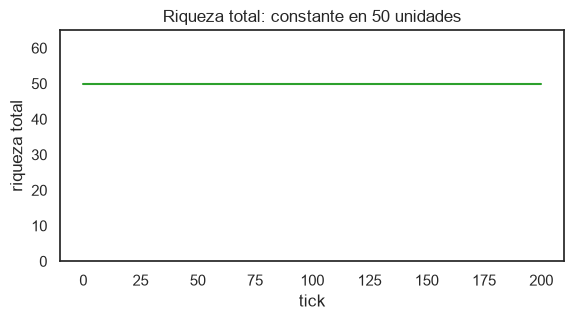

mínimo: 50.0  máximo: 50.0  ¿constante? True


In [19]:
d = series(ModeloConfig(50, rng=0), 200)
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.plot(d.tick, d.total, color="#2ca02c")
ax.set(xlabel="tick", ylabel="riqueza total", ylim=(0, d.total.max() * 1.3),
       title=f"Riqueza total: constante en {d.total.iloc[0]:.0f} unidades")
plt.show()
print("mínimo:", d.total.min(), " máximo:", d.total.max(), " ¿constante?", d.total.nunique() == 1)

**2. ¿Qué cambia con otra riqueza inicial?** La *forma* de la distribución no cambia —sigue
siendo exponencial (Boltzmann–Gibbs), la misma recta en escala logarítmica—; cambian la
escala y la velocidad.

El Gini estacionario se acerca a 0.5, que es el valor de una exponencial, y lo hace desde
arriba: **0.621 ± 0.002** con `w0 = 1`, **0.534 ± 0.006** con `w0 = 5` y **0.510 ± 0.007**
con `w0 = 10`. El exceso de `w0 = 1` es discretización pura: con una sola unidad por cabeza,
la mitad de los agentes está en cero y no hay forma de repartir más fino. Con `w0` grande el
sistema tarda más en llegar: hay más unidades que barajar.

w0 =  1:  Gini estacionario = 0.621 ± 0.002


w0 =  5:  Gini estacionario = 0.534 ± 0.006


w0 = 10:  Gini estacionario = 0.510 ± 0.007


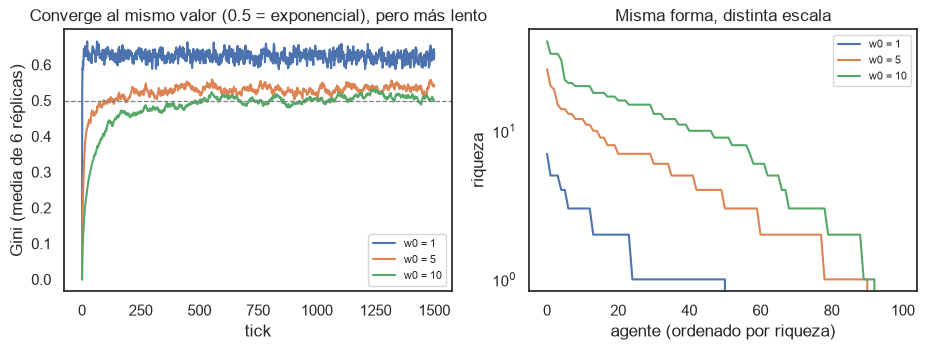

In [20]:
fig, (izq, der) = plt.subplots(1, 2, figsize=(11, 3.4))
for w0 in (1, 5, 10):
    curvas = [series(ModeloConfig(100, w0=w0, rng=r), 1500).gini for r in range(6)]
    izq.plot(pd.concat(curvas, axis=1).mean(axis=1), label=f"w0 = {w0}")
    media, err = resumen(curvas, desde=1000)
    print(f"w0 = {w0:>2}:  Gini estacionario = {media:.3f} ± {err:.3f}")

    m = ModeloConfig(100, w0=w0, rng=0)
    for _ in range(1500):
        m.step()
    der.plot(sorted((a.wealth for a in m.agents), reverse=True), label=f"w0 = {w0}")

izq.axhline(0.5, color="grey", ls="--", lw=0.9)
izq.set(xlabel="tick", ylabel="Gini (media de 6 réplicas)",
        title="Converge al mismo valor (0.5 = exponencial), pero más lento")
der.set(xlabel="agente (ordenado por riqueza)", ylabel="riqueza", yscale="log",
        title="Misma forma, distinta escala")
izq.legend(fontsize=8)
der.legend(fontsize=8)
plt.show()

**3. ¿Cuántos agentes quedan en cero?** La fracción sube rápido y se estabiliza. Si la
estacionaria fuera una geométrica de media `w0`, la predicción sería
$P(0) = 1/(1+w_0)$ — y el orden de magnitud acierta, aunque la simulación queda
sistemáticamente por debajo: **0.458** contra 0.500 (`w0=1`), **0.218** contra 0.250
(`w0=3`), **0.070** contra 0.091 (`w0=10`).

Es decir: la aproximación de campo medio sirve para anticipar el orden, no para dar el
número exacto. (La diferencia no viene de que el agente pueda elegirse a sí mismo: al
prohibirlo, la cifra baja todavía más en vez de subir.)

w0= 1: observado 0.458   geométrica 1/(1+w0) = 0.500
w0= 3: observado 0.218   geométrica 1/(1+w0) = 0.250


w0=10: observado 0.070   geométrica 1/(1+w0) = 0.091


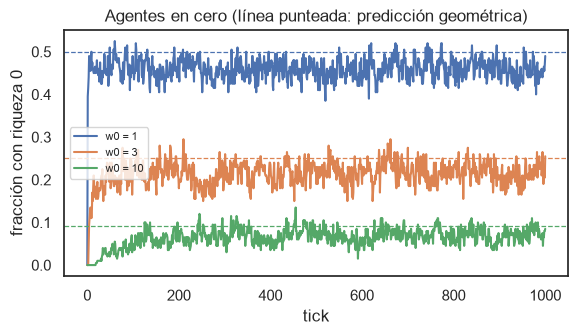

In [21]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
for w0 in (1, 3, 10):
    d = series(ModeloConfig(200, w0=w0, rng=0), 1000)
    linea, = ax.plot(d.tick, d.ceros, label=f"w0 = {w0}")
    ax.axhline(1 / (1 + w0), color=linea.get_color(), ls="--", lw=0.9)
    print(f"w0={w0:>2}: observado {d.ceros.iloc[-200:].mean():.3f}   geométrica 1/(1+w0) = {1/(1+w0):.3f}")
ax.set(xlabel="tick", ylabel="fracción con riqueza 0",
       title="Agentes en cero (línea punteada: predicción geométrica)")
ax.legend(fontsize=8)
plt.show()

**4. Transacción con costo (−1 al que da, +0.9 al que recibe).** La riqueza deja de
conservarse: cae de 100 a **56.9** unidades en 300 ticks, y sigue bajando.

Hay que tomar una decisión que el enunciado no fija: **qué significa «tener dinero» cuando
la riqueza deja de ser entera.** Con el `wealth > 0` del tutorial, un agente con 0.9 entrega
1 y queda en −0.1; repetido, el total se hunde por debajo de cero y el Gini deja de tener
sentido. La condición pasa a ser `wealth >= 1`.

Consecuencia interesante: con esa regla, quien cae por debajo de 1 queda **congelado**, y el
Gini medido baja a 0.186 ± 0.010 frente a 0.625 ± 0.002 del caso sin costo. El índice
«mejora» mientras el sistema empeora — todos terminan igual de pobres. Un buen recordatorio
de que un agregado no es un diagnóstico.

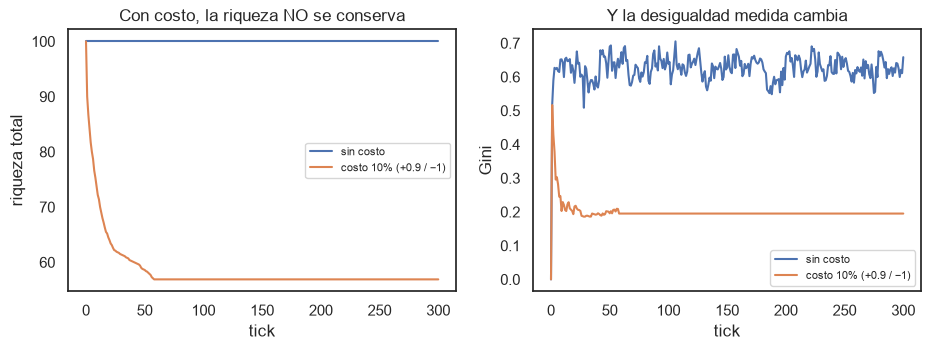

total inicial 100.0 -> final 56.9 (56.9% de lo inicial)


In [22]:
fig, (izq, der) = plt.subplots(1, 2, figsize=(11, 3.4))
for costo, etiqueta in ((0.0, "sin costo"), (0.1, "costo 10% (+0.9 / −1)")):
    d = series(ModeloConfig(100, costo=costo, rng=0), 300)
    izq.plot(d.tick, d.total, label=etiqueta)
    der.plot(d.tick, d.gini, label=etiqueta)
izq.set(xlabel="tick", ylabel="riqueza total", title="Con costo, la riqueza NO se conserva")
der.set(xlabel="tick", ylabel="Gini", title="Y la desigualdad medida cambia")
izq.legend(fontsize=8)
der.legend(fontsize=8)
plt.show()

d = series(ModeloConfig(100, costo=0.1, rng=0), 300)
print(f"total inicial {d.total.iloc[0]:.1f} -> final {d.total.iloc[-1]:.1f} "
      f"({100 * d.total.iloc[-1] / d.total.iloc[0]:.1f}% de lo inicial)")

**5. Una modificación propia.** En vez de elegir un candidato, elegir **dos** y dar al más
pobre de los dos. Sigue siendo una regla estrictamente local —el agente no ve el sistema,
solo a dos contrapartes— y no cambia ni la cantidad de dinero ni el número de transacciones.

Con eso solo, el Gini estacionario pasa de **0.625 ± 0.002** a **0.402 ± 0.001**. Una regla
local mínima mueve el resultado agregado tanto como lo haría una redistribución central, y
eso es exactamente lo que un ABM sirve para mostrar: el puente entre la regla micro y el
patrón macro.

            original: Gini estacionario = 0.625 ± 0.002


       con costo 10%: Gini estacionario = 0.186 ± 0.010


 al más pobre de dos: Gini estacionario = 0.402 ± 0.001


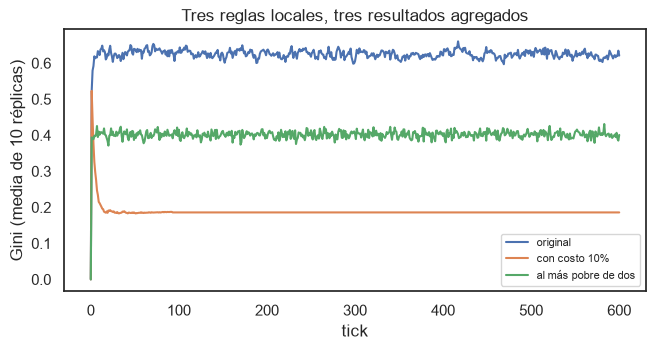

In [23]:
# Propuesta: en vez de un candidato, mirar DOS y dar al más pobre de los dos. Sigue siendo
# una regla local —el agente no ve el sistema, solo a dos contrapartes— y basta para
# cambiar el resultado agregado.
variantes = {
    "original": dict(),
    "con costo 10%": dict(costo=0.1),
    "al más pobre de dos": dict(mejor_de_dos=True),
}
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for nombre, kw in variantes.items():
    curvas = [series(ModeloConfig(100, rng=r, **kw), 600).gini for r in range(10)]
    ax.plot(pd.concat(curvas, axis=1).mean(axis=1), label=nombre)
    media, err = resumen(curvas, desde=400)
    print(f"{nombre:>20}: Gini estacionario = {media:.3f} ± {err:.3f}")
ax.set(xlabel="tick", ylabel="Gini (media de 10 réplicas)",
       title="Tres reglas locales, tres resultados agregados")
ax.legend(fontsize=8)
plt.show()

## Agentes moviéndose en el espacio

**Antecedentes**: Muchos ABM tienen un componente espacial; los agentes se mueven e interactúan con sus vecinos cercanos. Mesa cuenta con varios tipos de espacios. Podemos dividir el espacio en cuadrículas o celdas, tal que los agentes solo pueden estar en una celda específica, como piezas en un tablero de ajedrez. También se puede considerar un  espacio continuo que permite que los agentes tengan cualquier posición arbitraria.

Es importante tener en cuenta la **condición de frontera del espacio**. Con frecuencia se considera la condición [toroidal](https://en.wikipedia.org/wiki/Toroidal_graph), lo que significa que los bordes se envuelven. Esto evita que algunas celdas tengan menos vecinos que otras, o que los agentes puedan salirse del borde del entorno. Puede imaginar un toroide pensando en una dona.


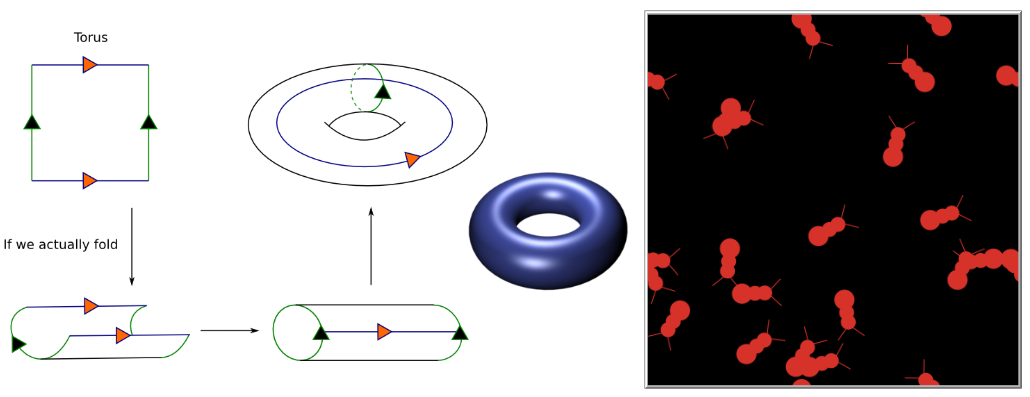

Mesa tiene dos tipos principales de cuadrículas: SingleGrid y MultiGrid. SingleGrid impone como máximo un agente por celda; MultiGrid permite que varios agentes estén en la misma celda. Podemos usar MultiGrid para intercambiar dinero sólo con los agentes en la misma celda.

**Información específica del modelo**: Añadamos un elemento espacial simple a nuestro modelo: colocamos a nuestros agentes en una cuadrícula y los hacemos desplazarse aleatoriamente. En lugar de dar su unidad de dinero a cualquier agente aleatorio, la darán dinero a un agente en la misma celda.

**Implementación del código**: Obtenemos un entero aleatorio con el ancho y la altura del espacio de la cuadrícula y usamos la función multigrid place_agent de Mesa para colocar al agente en la ubicación especificada de la cuadrícula.

In [24]:
class MoneyModel(mesa.Model):
    """A model with some number of agents."""

    def __init__(self, n, width, height, seed=None):
        super().__init__(seed=seed)
        self.num_agents = n
        self.grid = mesa.space.MultiGrid(width, height, True)
        # True corresponde al argumento Torus.
        # mesa.space.MultiGrid(width, height, torus)

        # Create agents
        agents = MoneyAgent.create_agents(model=self, n=n)
        # Create x and y positions for agents
        # rng: random number generator
        x = self.rng.integers(0, self.grid.width, size=(n,))
        y = self.rng.integers(0, self.grid.height, size=(n,))
        for a, i, j in zip(agents, x, y):
            # Add the agent to a random grid cell
            self.grid.place_agent(a, (i, j))

### Movimiento de los agentes

En el entorno operativo, la posición de cada agente se almacena de dos maneras: el agente se encuentra en la cuadrícula, en la celda donde se encuentra, y tiene una variable pos con una tupla de coordenadas (x, y). El método place_agent añade la coordenada al agente automáticamente.

Ahora necesitamos modificar el comportamiento de los agentes, permitiéndoles moverse y que solo otorguen dinero a otros agentes en la misma celda.

Primero, gestionaremos el movimiento y haremos que los agentes se muevan a una celda vecina. El objeto de la cuadrícula proporciona un método move_agent que, como es de esperar, mueve un agente a una celda determinada. Aún nos queda determinar las posibles celdas vecinas a las que moverse. Hay un par de maneras de hacerlo. Una es usar las coordenadas actuales y recorrer todas las coordenadas a +/- 1 de distancia de ellas.

Pero existe una forma aún más sencilla: usar el método get_neighborhood integrado en la cuadrícula, que devuelve todos los vecinos de una celda dada. Este método puede obtener **dos tipos de vecindades** de celda: **[Moore](https://en.wikipedia.org/wiki/Moore_neighborhood)** (incluye los 8 cuadrados circundantes) y **[Von Neumann](https://en.wikipedia.org/wiki/Von_Neumann_neighborhood)** (solo arriba/abajo/izquierda/derecha). También necesita un argumento para indicar si se incluye la celda central como vecina.

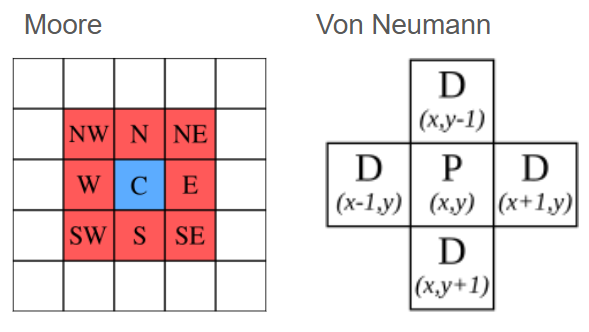


A continuación, necesitamos obtener todos los demás agentes presentes en una celda y asignarle dinero a uno de ellos. Podemos obtener el contenido de una o más celdas mediante el método get_cell_list_contents de la cuadrícula o accediendo directamente a una celda. El método acepta una lista de tuplas de coordenadas de celdas o una sola tupla si solo nos interesa una celda.

In [25]:
class MoneyAgent(mesa.Agent):
    """An agent with fixed initial wealth."""

    def __init__(self, model):
        super().__init__(model)
        self.wealth = 1

    def move(self):
        possible_steps = self.model.grid.get_neighborhood(
            self.pos, moore=True, include_center=False
        )
        new_position = self.random.choice(possible_steps)
        self.model.grid.move_agent(self, new_position)

    def give_money(self):
        cellmates = self.model.grid.get_cell_list_contents([self.pos])
        # Ensure agent is not giving money to itself
        cellmates.pop(cellmates.index(self))
        if len(cellmates) > 0:
            other_agent = self.random.choice(cellmates)
            other_agent.wealth += 1
            self.wealth -= 1


class MoneyModel(mesa.Model):
    """A model with some number of agents."""

    def __init__(self, n, width, height, seed=None):
        super().__init__(seed=seed)
        self.num_agents = n
        self.grid = mesa.space.MultiGrid(width, height, True)

        # Create agents
        agents = MoneyAgent.create_agents(model=self, n=n)
        # Create x and y coordinates for agents
        x = self.rng.integers(0, self.grid.width, size=(n,))
        y = self.rng.integers(0, self.grid.height, size=(n,))
        for a, i, j in zip(agents, x, y):
            # Add the agent to a random grid cell
            self.grid.place_agent(a, (i, j))

    def step(self):
        self.agents.shuffle_do("move")
        self.agents.do("give_money")

Creemos un modelo con 100 agentes en una cuadrícula de 10x10 y ejecutémoslo durante 20 pasos.

In [26]:
model = MoneyModel(100, 10, 10)
for _ in range(20):
    model.step()

Ahora usemos seaborn y numpy para visualizar el número de agentes que residen en cada celda. Para ello, creamos un array numpy del mismo tamaño que la cuadrícula, lleno de ceros. Luego, usamos la función `coord_iter()` del objeto de la cuadrícula, que nos permite recorrer cada celda de la cuadrícula, obteniendo la posición y el contenido de cada una.

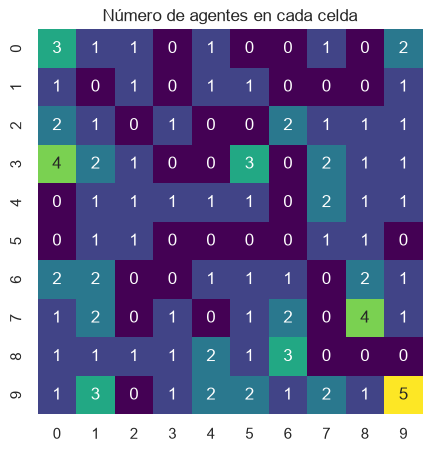

In [27]:
agent_counts = np.zeros((model.grid.width, model.grid.height))
for cell_content, (x, y) in model.grid.coord_iter():
    agent_count = len(cell_content)
    agent_counts[x][y] = agent_count
# Plot using seaborn, with a visual size of 5x5
g = sns.heatmap(agent_counts, cmap="viridis", annot=True, cbar=False, square=True)
g.figure.set_size_inches(5, 5)
g.set(title="Número de agentes en cada celda");

> Este heatmap es una foto del último tick. La versión **animada** —el mismo
> `agent_counts` recalculado en cada paso, junto a las posiciones y a las transferencias—
> está al final del cuaderno, en «El espacio de estados y de acciones, con espacio». Ahí se
> ve que el número de celdas vacías no baja nunca: ronda 37 de 100 toda la corrida.

El total de agentes en la cuadrícula debe permanecer constante

In [28]:
print(agent_counts.sum())

100.0


 <font color="red"> **Ejercicios 2** </font>

1. Haga seguimiento a la conservación total de la riqueza.
2. Varíe la riqueza inicial y observe si hay cambios en la dinámica.
3. Cuente cuántas celdas quedaron vacías.
4. Use vecindarios de Von Neumann y observe si hay cambios en la dinámica.
5. Haga que el movimiento dependa de la riqueza. Si un agente tiene wealth > 2 hay un 50% de posibilidad de que se quede en su lugar.

### <font color="green"> Respuestas </font>

Otra vez un solo modelo parametrizado: el tipo de vecindario, la riqueza inicial y la regla
de movimiento según riqueza son argumentos.

In [29]:
# Igual que antes: un modelo con grilla parametrizado cubre los cinco ejercicios.
class AgenteEspacioConfig(MoneyAgent):
    def move(self):
        # Ejercicio 5: quien tiene más de 2 unidades se queda quieto la mitad de las veces.
        if self.model.quieto_si_rico and self.wealth > 2 and self.random.random() < 0.5:
            return
        vecinas = self.model.grid.get_neighborhood(
            self.pos, moore=self.model.moore, include_center=False
        )
        self.model.grid.move_agent(self, self.random.choice(vecinas))

    def give_money(self):
        if self.wealth < 1:
            return
        companeros = self.model.grid.get_cell_list_contents([self.pos])
        companeros.pop(companeros.index(self))
        if companeros:
            otro = self.random.choice(companeros)
            otro.wealth += 1
            self.wealth -= 1


class ModeloEspacioConfig(mesa.Model):
    def __init__(self, n, width, height, w0=1, moore=True, quieto_si_rico=False, rng=None):
        super().__init__(rng=rng)
        self.num_agents = n
        self.moore = moore
        self.quieto_si_rico = quieto_si_rico
        self.grid = mesa.space.MultiGrid(width, height, True)

        agentes = AgenteEspacioConfig.create_agents(model=self, n=n)
        x = self.rng.integers(0, self.grid.width, size=(n,))
        y = self.rng.integers(0, self.grid.height, size=(n,))
        for a, i, j in zip(agentes, x, y):
            a.wealth = w0
            self.grid.place_agent(a, (i, j))

    def step(self):
        self.agents.shuffle_do("move")
        self.agents.do("give_money")


def series_espacio(modelo, pasos):
    """Riqueza total, Gini y celdas vacías, tick a tick."""
    filas = []
    for t in range(pasos + 1):
        w = [a.wealth for a in modelo.agents]
        filas.append({"tick": t, "total": sum(w), "gini": gini_de(w),
                      "vacias": len(modelo.grid.empties)})
        if t < pasos:
            modelo.step()
    return pd.DataFrame(filas)


def resumen(curvas, desde=200):
    """Media entre réplicas del valor promedio de la ventana final, con error estándar.

    Mirar el último tick de una sola corrida es leer ruido: entre réplicas el Gini se
    mueve varias centésimas. Se promedia la ventana estacionaria y se reportan réplicas.
    """
    valores = [c[desde:].mean() for c in curvas]
    return np.mean(valores), np.std(valores) / len(valores) ** 0.5

**1. Conservación con espacio.** Igual que sin él: `give_money` mueve una unidad de un
bolsillo a otro y el total no se altera — 100 unidades durante los 301 ticks. Lo que el
espacio cambia no es cuánto dinero hay, sino **con quién se puede intercambiar**.

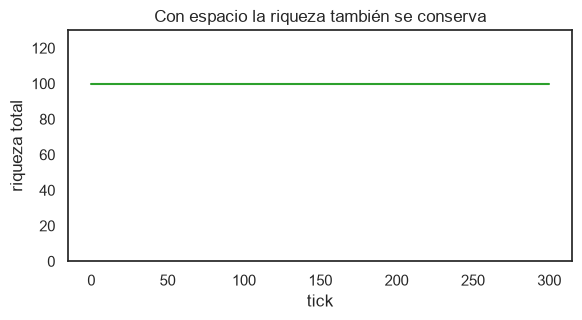

¿constante? True | valor: 100


In [30]:
d = series_espacio(ModeloEspacioConfig(100, 10, 10, rng=0), 300)
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.plot(d.tick, d.total, color="#2ca02c")
ax.set(xlabel="tick", ylabel="riqueza total", ylim=(0, d.total.max() * 1.3),
       title="Con espacio la riqueza también se conserva")
plt.show()
print("¿constante?", d.total.nunique() == 1, "| valor:", d.total.iloc[0])

**2. Riqueza inicial sobre la grilla.** Mismo patrón que sin espacio, pero más lento: a 1500
ticks el Gini va en **0.572 ± 0.005** (`w0=1`), **0.526 ± 0.005** (`w0=5`) y
**0.452 ± 0.008** (`w0=10`), este último todavía subiendo. El espacio añade un cuello de
botella —hay que coincidir en la misma celda para poder dar—, así que la relajación tarda
más que en el modelo bien mezclado.

w0 =  1:  Gini estacionario = 0.572 ± 0.005


w0 =  5:  Gini estacionario = 0.526 ± 0.005


w0 = 10:  Gini estacionario = 0.452 ± 0.008


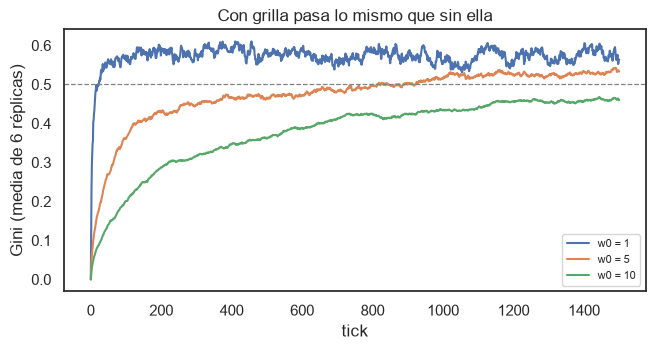

In [31]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for w0 in (1, 5, 10):
    curvas = [series_espacio(ModeloEspacioConfig(100, 10, 10, w0=w0, rng=r), 1500).gini
              for r in range(6)]
    ax.plot(pd.concat(curvas, axis=1).mean(axis=1), label=f"w0 = {w0}")
    media, err = resumen(curvas, desde=1000)
    print(f"w0 = {w0:>2}:  Gini estacionario = {media:.3f} ± {err:.3f}")
ax.axhline(0.5, color="grey", ls="--", lw=0.9)
ax.set(xlabel="tick", ylabel="Gini (media de 6 réplicas)",
       title="Con grilla pasa lo mismo que sin ella")
ax.legend(fontsize=8)
plt.show()

**3. ¿Cuántas celdas quedan vacías?** Unas **37 de 100**, y se mantiene ahí toda la corrida.
No es un accidente: si $N$ agentes se reparten al azar entre $M$ celdas, la probabilidad de
que una celda quede vacía es $(1-1/M)^N$, que con $N = M = 100$ da **36.6** celdas
($M e^{-N/M} = 36.8$). La simulación mide **36.3**.

Es decir: el movimiento aleatorio mantiene la ocupación exactamente en el valor del azar
puro. No hay agregación ni dispersión emergente — si la hubiera, esta comparación sería la
forma de detectarla.

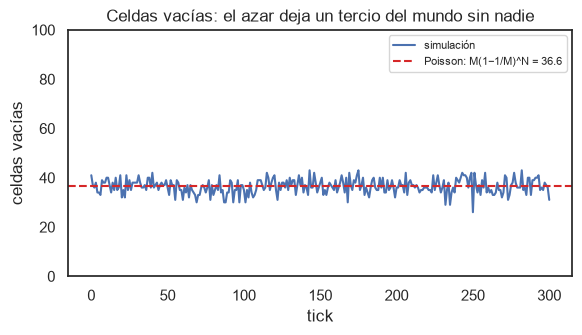

media observada (ticks 50+): 36.3   predicción: 36.6   ·  M·e^(−N/M) = 36.8


In [32]:
import math

d = series_espacio(ModeloEspacioConfig(100, 10, 10, rng=0), 300)
celdas, n = 100, 100
prediccion = celdas * (1 - 1 / celdas) ** n  # ≈ M·e^(−N/M)

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(d.tick, d.vacias, label="simulación")
ax.axhline(prediccion, color="#d62728", ls="--",
           label=f"Poisson: M(1−1/M)^N = {prediccion:.1f}")
ax.set(xlabel="tick", ylabel="celdas vacías", ylim=(0, celdas),
       title="Celdas vacías: el azar deja un tercio del mundo sin nadie")
ax.legend(fontsize=8)
plt.show()
print(f"media observada (ticks 50+): {d.vacias[50:].mean():.1f}   "
      f"predicción: {prediccion:.1f}   ·  M·e^(−N/M) = {celdas * math.exp(-n / celdas):.1f}")

**4. Von Neumann en vez de Moore.** Depende de la densidad, y ese es el punto interesante:

* Grilla **10×10** (1 agente por celda): 0.585 ± 0.007 con Moore contra 0.566 ± 0.006 con
  Von Neumann. La diferencia es de dos errores estándar: marginal.
* Grilla **25×25** (0.16 agentes por celda): 0.391 ± 0.008 contra 0.350 ± 0.011. Ahora sí se
  separan.

Con la grilla llena da casi igual cómo te muevas, porque siempre hay con quién intercambiar.
Con la grilla vacía, moverse a 4 vecinos en vez de 8 reduce la tasa de encuentros y la
desigualdad crece más despacio. La estructura del vecindario importa **solo cuando el
encuentro es el recurso escaso**.

10×10   Moore (8 vecinos): Gini = 0.585 ± 0.007


10×10     Von Neumann (4): Gini = 0.566 ± 0.006


25×25   Moore (8 vecinos): Gini = 0.391 ± 0.008


25×25     Von Neumann (4): Gini = 0.350 ± 0.011


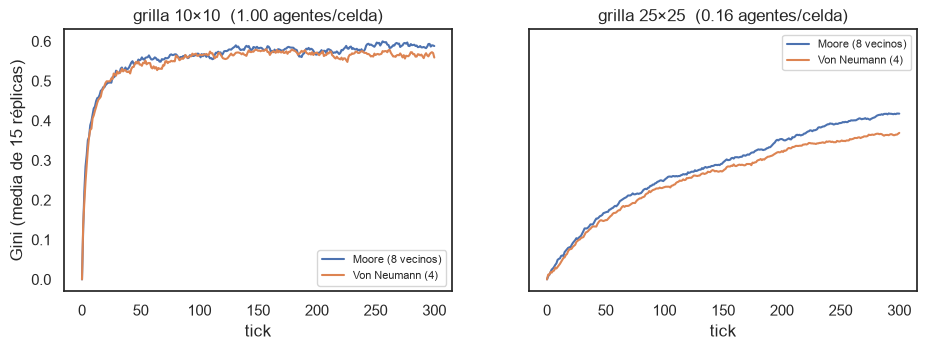

In [33]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, lado in zip(ejes, (10, 25)):
    for moore, etiqueta in ((True, "Moore (8 vecinos)"), (False, "Von Neumann (4)")):
        curvas = [
            series_espacio(
                ModeloEspacioConfig(100, lado, lado, moore=moore, rng=r), 300
            ).gini
            for r in range(15)
        ]
        ax.plot(pd.concat(curvas, axis=1).mean(axis=1), label=etiqueta)
        media, err = resumen(curvas)
        print(f"{lado}×{lado}  {etiqueta:>18}: Gini = {media:.3f} ± {err:.3f}")
    ax.set(xlabel="tick", title=f"grilla {lado}×{lado}  ({100 / lado**2:.2f} agentes/celda)")
    ax.legend(fontsize=8)
ejes[0].set_ylabel("Gini (media de 15 réplicas)")
plt.show()

**5. Movimiento que depende de la riqueza.** No cambia nada medible: **0.575 ± 0.008** con
la regla contra **0.585 ± 0.007** sin ella, una diferencia de un error estándar.

La razón está en a cuántas acciones alcanza la regla. En el estado estacionario solo un ~9 %
de los agentes tiene más de 2 unidades, y esos se quedan quietos la mitad de las veces: la
regla toca alrededor del **4 % de los movimientos**. Para que una modificación así mueva la
dinámica tiene que afectar a una fracción grande de las acciones, o al recurso escaso — que
aquí, como mostró el punto 4, es el encuentro.

             todos se mueven: Gini = 0.585 ± 0.007


  quieto si wealth > 2 (50%): Gini = 0.575 ± 0.008


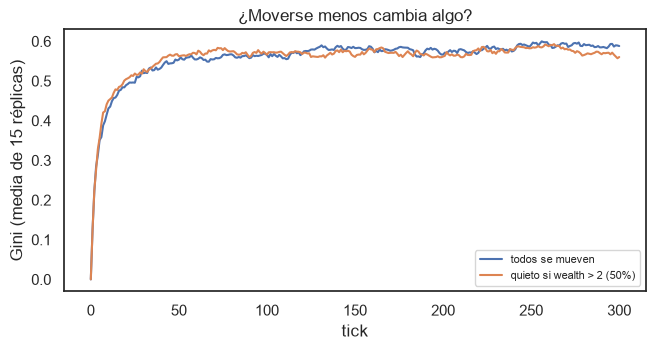


agentes con wealth > 2 en el estado estacionario: 9%  -> la regla toca ~4% de los movimientos


In [34]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for quieto, etiqueta in ((False, "todos se mueven"), (True, "quieto si wealth > 2 (50%)")):
    curvas = [series_espacio(
        ModeloEspacioConfig(100, 10, 10, quieto_si_rico=quieto, rng=r), 300).gini
        for r in range(15)]
    ax.plot(pd.concat(curvas, axis=1).mean(axis=1), label=etiqueta)
    media, err = resumen(curvas)
    print(f"{etiqueta:>28}: Gini = {media:.3f} ± {err:.3f}")
ax.set(xlabel="tick", ylabel="Gini (media de 15 réplicas)",
       title="¿Moverse menos cambia algo?")
ax.legend(fontsize=8)
plt.show()

# ¿A cuántos agentes afecta siquiera la regla?
m = ModeloEspacioConfig(100, 10, 10, rng=0)
for _ in range(300):
    m.step()
ricos = np.mean([a.wealth > 2 for a in m.agents])
print(f"\nagentes con wealth > 2 en el estado estacionario: {100 * ricos:.0f}%  "
      f"-> la regla toca ~{100 * ricos / 2:.0f}% de los movimientos")

# Recolección de datos

**Antecedentes:** Hasta ahora, al final de cada ejecución del modelo, hemos tenido que escribir nuestro propio código para extraer los datos. Esto presenta dos problemas: no es muy eficiente y solo nos proporciona resultados finales. Si quisiéramos conocer la riqueza de cada agente en cada paso, tendríamos que añadirla al bucle de pasos en ejecución y encontrar una forma de almacenar los datos.

Dado que uno de los objetivos principales del modelado basado en agentes es generar datos para su análisis, Mesa proporciona una clase que gestiona la recopilación y el almacenamiento de datos, facilitando así su análisis.

El recopilador de datos almacena tres categorías de datos:

- **Variables a nivel de modelo**: Las funciones de recopilación a nivel de modelo toman un objeto del modelo como entrada. Por ejemplo, una función que calcula la dinámica de todo el modelo (en este caso, calcularemos una medida de la desigualdad de la riqueza basada en la riqueza de todos los agentes).

- **Variables a nivel de agente**: Las funciones de recopilación a nivel de agente toman un objeto del agente como entrada, que suele ser el estado de los atributos de un agente, en este caso, la riqueza. Tablas (que sirven como un "comodín" para todo lo demás).

**Información específica del modelo:** Recopilaremos dos variables para mostrar las capacidades de Mesa. A nivel de modelo, mediremos el [Coeficiente de Gini](https://en.wikipedia.org/wiki/Gini_coefficient), una medida de la desigualdad de la riqueza. A nivel de agente, queremos recopilar la riqueza de cada agente en cada paso.

**Implementación de código:**
Añadiremos un DataCollector al modelo con `mesa.DataCollector` y recopilaremos la riqueza del agente y el coeficiente de Gini en cada paso de tiempo.

Coeficiente Gini
$$G = 1 + \frac{1}{n} - 2 \frac{\sum_{i=0}^{n-1} x_i(n-i)}{n\sum_{i=0}^{n-1}x_i} $$

Interpretación:
* $G = 0$: Distribución perfectamente igualitaria, todos tienen lo mismo.
* $G$ crece a medida que la desigualdad es mayor.

In [35]:
def compute_gini(model):
    agent_wealths = [agent.wealth for agent in model.agents]
    x = sorted(agent_wealths)
    n = model.num_agents
    B = sum(xi * (n - i) for i, xi in enumerate(x)) / (n * sum(x))
    return 1 + (1 / n) - 2 * B


class MoneyAgent(mesa.Agent):
    """An agent with fixed initial wealth."""

    def __init__(self, model):
        super().__init__(model)
        self.wealth = 1

    def move(self):
        possible_steps = self.model.grid.get_neighborhood(
            self.pos, moore=True, include_center=False
        )
        new_position = self.random.choice(possible_steps)
        self.model.grid.move_agent(self, new_position)

    def give_money(self):
      if self.wealth > 0 :
          cellmates = self.model.grid.get_cell_list_contents([self.pos])
         # Ensure agent is not giving money to itself
          cellmates.pop(cellmates.index(self))
          if len(cellmates) > 0:
            other = self.random.choice(cellmates)
           # if other.wealth < 4:
            other.wealth += 1
            self.wealth -= 1


class MoneyModel(mesa.Model):
    """A model with some number of agents."""

    def __init__(self, n, width, height):
        super().__init__()
        self.num_agents = n
        # create the space
        self.grid = mesa.space.MultiGrid(width, height, True)
        # collect the output
        self.datacollector = mesa.DataCollector(
            model_reporters={"Gini": compute_gini}, agent_reporters={"Wealth": "wealth"}
        )

        # Create agents
        agents = MoneyAgent.create_agents(model=self, n=n)
        # Create x and y positions for agents
        x = self.rng.integers(0, self.grid.width, size=(n,))
        y = self.rng.integers(0, self.grid.height, size=(n,))
        for a, i, j in zip(agents, x, y):
            # Add the agent to a random grid cell
            self.grid.place_agent(a, (i, j))

    def step(self):
        self.datacollector.collect(self)
        self.agents.shuffle_do("move")
        self.agents.do("give_money")

Experimento

In [36]:
model = MoneyModel(100, 10, 10)
for _ in range(500):
    model.step()

Graficamos la variable global calculada

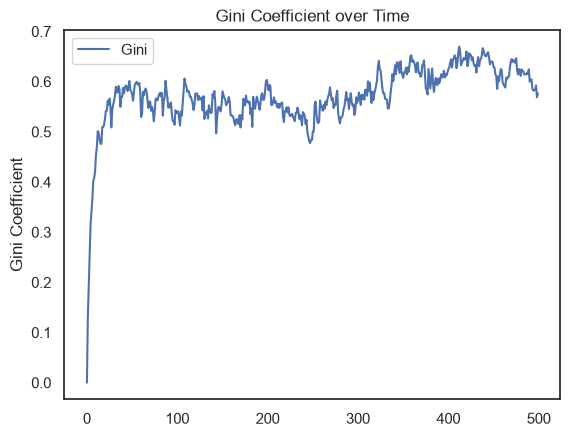

In [37]:
gini = model.datacollector.get_model_vars_dataframe()
# Plot the Gini coefficient over time
g = sns.lineplot(data = gini)
g.set(title="Gini Coefficient over Time", ylabel="Gini Coefficient");

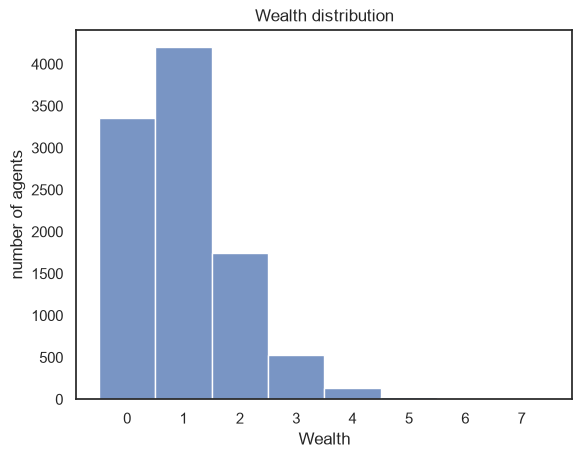

In [38]:
all_wealth = []
# This runs the model 100 times, each model executing 10 steps.
for _ in range(100):
    # Run the model
    model = MoneyModel(100, 10, 10)
    for _ in range(20):
        model.step()

    # Store the results
    for agent in model.agents:
        all_wealth.append(agent.wealth)

# Use seaborn
g = sns.histplot(all_wealth, discrete=True)
g.set(title="Wealth distribution", xlabel="Wealth", ylabel="number of agents");

## El espacio de estados y de acciones, con espacio

Con la grilla, el estado del modelo crece: ya no basta con saber cuánto tiene cada agente,
hay que saber **dónde está**.

* **Estado** *s* = (posición, riqueza) de cada agente. Con 100 agentes en 100 celdas son
  $100^{100} \approx 10^{200}$ configuraciones de posiciones por cada uno de los
  $\approx 10^{59}$ repartos de riqueza: $|S| \approx 10^{259}$. El panel de abajo a la
  derecha lleva la cuenta.
* **Acción** *a* = (moverse a una de las 8 celdas vecinas) × (dar una unidad a un compañero
  de celda, o a nadie si está solo). El espacio de acciones **depende del estado**: un
  agente solo en su celda no puede dar aunque quiera, y eso es lo que el espacio añade al
  modelo.

La flecha naranja vuelve a ser una transferencia; la línea gris tenue, un movimiento. Al
lado va el **heatmap de `agent_counts`** de la sección anterior, pero vivo: el mismo estado
visto como densidad, con las celdas vacías incluidas.

In [39]:
class AgenteEspacioTraza(MoneyAgent):
    """El agente final del tutorial (move + give_money) con bitácora de acciones."""

    def move(self):
        antes = self.pos
        super().move()  # la regla de movimiento no cambia: se hereda tal cual
        self.model.movimientos.append((self.unique_id, antes, self.pos))

    def give_money(self):
        # Aquí no basta con super(): el método original no dice QUIÉN recibió, y eso es
        # justo lo que hay que dibujar. La lógica es idéntica.
        if self.wealth > 0:
            cellmates = self.model.grid.get_cell_list_contents([self.pos])
            cellmates.pop(cellmates.index(self))
            if len(cellmates) > 0:
                otro = self.random.choice(cellmates)
                otro.wealth += 1
                self.wealth -= 1
                self.model.transferencias.append(
                    (self.pos, otro.pos, self.unique_id, otro.unique_id)
                )


class ModeloEspacioTraza(mesa.Model):
    """El modelo con grilla, instrumentado para poder animarlo."""

    def __init__(self, n, width, height, rng=None):
        super().__init__(rng=rng)
        self.num_agents = n
        self.grid = mesa.space.MultiGrid(width, height, True)
        self.movimientos, self.transferencias = [], []

        agents = AgenteEspacioTraza.create_agents(model=self, n=n)
        x = self.rng.integers(0, self.grid.width, size=(n,))
        y = self.rng.integers(0, self.grid.height, size=(n,))
        for a, i, j in zip(agents, x, y):
            self.grid.place_agent(a, (i, j))

    def step(self):
        self.movimientos, self.transferencias = [], []
        self.agents.shuffle_do("move")
        self.agents.do("give_money")


modelo_con_espacio = ModeloEspacioTraza(100, 10, 10, rng=42)
animar_modelo(
    traza(modelo_con_espacio, 40),
    forma=(10, 10),
    titulo="Con espacio: 100 agentes en una grilla 10×10 toroidal",
)

**Lo que se ve.** El espacio no cambia la conclusión —la distribución sigue volviéndose
exponencial y el Gini sigue creciendo hasta estabilizarse— pero sí cambia el mecanismo: una
transferencia necesita primero un **encuentro**. Con 100 agentes en 100 celdas, cada tick
transfieren unos 55 de 100: los demás están solos en su celda y no tienen a quién dar. Ese
es el cuello de botella que el modelo sin espacio no tenía.

También se ve que ~37 celdas quedan vacías todo el tiempo, sin que nadie se agrupe a
propósito: es el reparto del azar puro, y los ejercicios de abajo lo verifican contra la
predicción de Poisson.